# Part 2

Three treatment arms for pre-diabetics: metformin (`met`), rosiglitazone (`rosi`), and lifestyle adjustments (`lifestyle`). `Outcome` is coded `success` = 1, `failure` = 0.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

**1.** Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups?

In [3]:
df = pd.read_csv('./Thursday_lab/data/diabetes.csv')
df['Success'] = (df['outcome'] == 'success').astype(int) # 1 = success, 0 = failure

## Crosstabs, average outcomes:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

print('Average outcomes:')
print(df.groupby('treatment')['Success'].mean().round(3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Average outcomes:
treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: Success, dtype: float64


**2.** Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms.

In [4]:
## Bootstrapping:
R = 10_000

df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]
df_life = df.loc[ df['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_life = []

for t in range(R):
    ## Resample within each arm:
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_life_t = df_life.sample(frac=1.0, replace=True)

    ## Evaluate and store outcomes:
    outcome_met.append(df_met_t['Success'].mean()) # Mean outcome for met
    outcome_rosi.append(df_rosi_t['Success'].mean()) # Mean outcome for rosi
    outcome_life.append(df_life_t['Success'].mean()) # Mean outcome for lifestyle

outcome_met = np.array(outcome_met)
outcome_rosi = np.array(outcome_rosi)
outcome_life = np.array(outcome_life)

**3.** Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

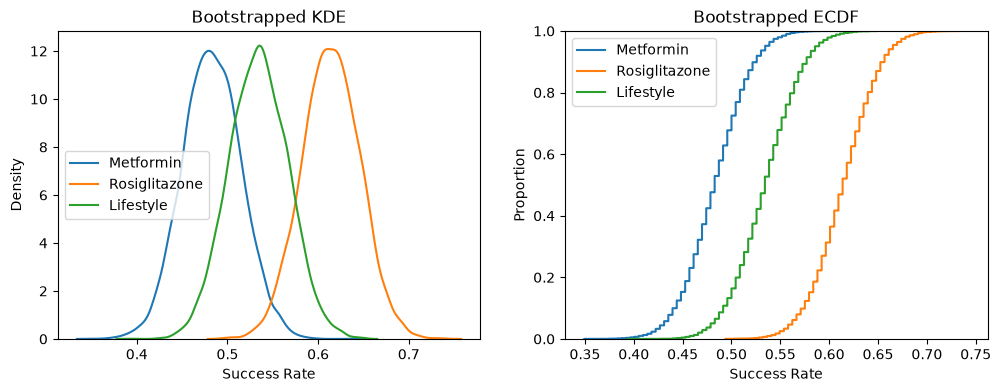

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

ax[0].legend()
ax[1].legend()
plt.show()

Rosiglitazone's distribution sits furthest to the right (success rate around 0.61), lifestyle is in the middle (around 0.53), and metformin is furthest left (around 0.48). All three are roughly bell-shaped with similar spreads, since the arms are about the same size. Rosi barely overlaps with met, while lifestyle overlaps a lot with both, so the clearest gap is between rosi and met.

**4.** There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

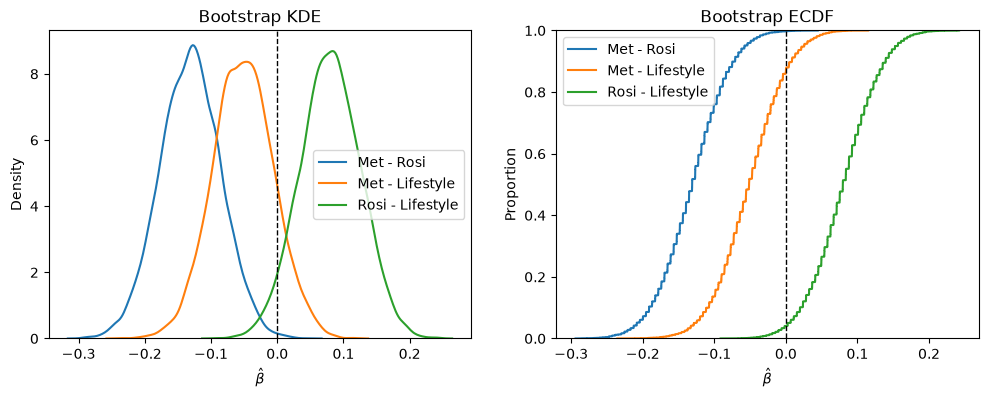

In [6]:
## Pairwise ATEs from the stored bootstrap estimates:
ate_met_rosi = outcome_met - outcome_rosi
ate_met_life = outcome_met - outcome_life
ate_rosi_life = outcome_rosi - outcome_life

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_met_rosi, label='Met - Rosi', ax=ax[0])
sns.kdeplot(ate_met_life, label='Met - Lifestyle', ax=ax[0])
sns.kdeplot(ate_rosi_life, label='Rosi - Lifestyle', ax=ax[0])
ax[0].axvline(0, color='black', linestyle='--', linewidth=1)
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate_met_rosi, label='Met - Rosi', ax=ax[1])
sns.ecdfplot(ate_met_life, label='Met - Lifestyle', ax=ax[1])
sns.ecdfplot(ate_rosi_life, label='Rosi - Lifestyle', ax=ax[1])
ax[1].axvline(0, color='black', linestyle='--', linewidth=1)
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

**5.** Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [7]:
ates = {'Met - Rosi': ate_met_rosi,
        'Met - Lifestyle': ate_met_life,
        'Rosi - Lifestyle': ate_rosi_life}

for name, ate in ates.items():
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    print(name)
    print(f"  Point estimate: {np.round(ate.mean(), 3)}")
    print(f"  90% CI: {np.round(ci90, 3)}")
    print(f"  95% CI: {np.round(ci95, 3)}")
    print(f"  99% CI: {np.round(ci99, 3)}")

Met - Rosi
  Point estimate: -0.131
  90% CI: [-0.208 -0.058]
  95% CI: [-0.221 -0.041]
  99% CI: [-0.247 -0.011]
Met - Lifestyle
  Point estimate: -0.051
  90% CI: [-0.128  0.026]
  95% CI: [-0.141  0.039]
  99% CI: [-0.172  0.064]
Rosi - Lifestyle
  Point estimate: 0.08
  90% CI: [0.003 0.156]
  95% CI: [-0.01   0.169]
  99% CI: [-0.036  0.195]


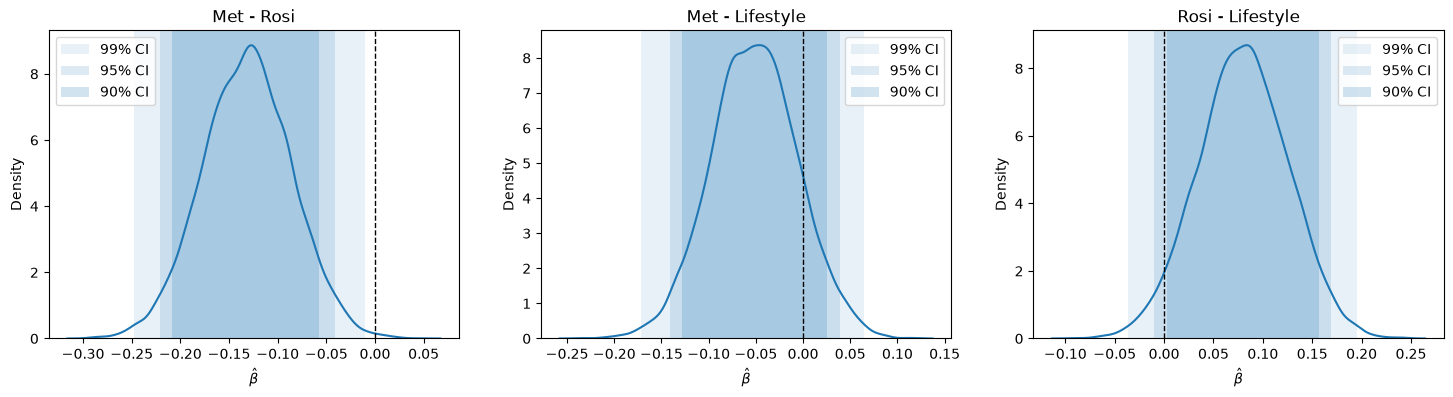

In [8]:
# Percentile bootstrap confidence intervals, shaded on each pairwise ATE
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

for i, (name, ate) in enumerate(ates.items()):
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    sns.kdeplot(ate, ax=ax[i])

    ax[i].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[i].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[i].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[i].axvline(0, color='black', linestyle='--', linewidth=1)

    ax[i].set_xlabel(r"$\hat{\beta}$")
    ax[i].set_title(name)
    ax[i].legend()

plt.show()

- **Met - Rosi:** about -0.13. Zero is outside the 90%, 95%, and 99% intervals, so we reject the null at every level. Rosiglitazone does significantly better than metformin.
- **Met - Lifestyle:** about -0.05. Zero is inside all three intervals, so we fail to reject the null. There's no significant difference.
- **Rosi - Lifestyle:** about 0.08. Zero is outside the 90% interval but inside the 95% and 99% intervals, so this one is only borderline significant (we reject only at the 10% level).

Rosiglitazone looks like the most effective treatment. It has the highest success rate, and its advantage over metformin is the only difference that holds up at the conventional 95% level.

**6.** Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not.


This review looks at a randomized controlled trial that compared metformin, rosiglitazone, and just plain lifestyle adjustment for preventing progression to diabetes. Each participant's outcome was recorded as a binary success or failure. The treatment effect for each pair of arms is estimated as the difference in success rates. To measure uncertainty, each arm was resampled with replacement 10,000 times by bootstrapping. Confidence intervals were taken from the percentiles of the resulting bootstrap distributions. Rosiglitazone had the highest observed success rate at 61.4%, followed by lifestyle at 53.4% and metformin at 48.3%. The pairwise comparisons are summarized below:

| Comparison | Difference in success rate | 95% CI | Significant at 5% |
|---|---|---|---|
| Metformin − Rosiglitazone | −0.131 | [−0.221, −0.041] | Yes |
| Metformin − Lifestyle | −0.051 | [−0.142, 0.039] | No |
| Rosiglitazone − Lifestyle | +0.080 | [−0.006, 0.170] | No |

Only the comparison between metformin and rosiglitazone is statistically significant. Rosiglitazone's success rate is about 13 percentage points higher, and zero is excluded even at the 99% level. Rosiglitazone's advantage over lifestyle is significant only at the 10% level. The trial provides no evidence of a difference between metformin and lifestyle adjustment.

Based on this study, Rosiglitazone is the only intervention with a demonstrated efficacy advantage, and only over metformin. However, the trial cannot rule out clinically meaningful differences in the other two comparisons. The confidence intervals are wide and lifestyle adjustment could plausibly be anywhere from about 14 points worse to 4 points better than metformin. A non-significant result reflects limited precision, not evidence that the treatments are equivalent. Lifestyle adjustment is low-cost and low-risk, so the absence of a significant difference is not a reason to discount it.

Several limitations should temper any recommendation to adopt a treatment. The data contain no adverse-event information, and this matters especially for rosiglitazone, which has a documented history of cardiovascular safety concerns and regulatory restrictions. Efficacy alone is not enough to justify its use. The data also do not allow a check of baseline balance across the arms or of how the outcome was defined. We recommend that any adoption decision be conditional on a review of the trial's safety data and outcome definitions. We also recommend that further trials be adequately powered to resolve the comparisons involving lifestyle adjustment.

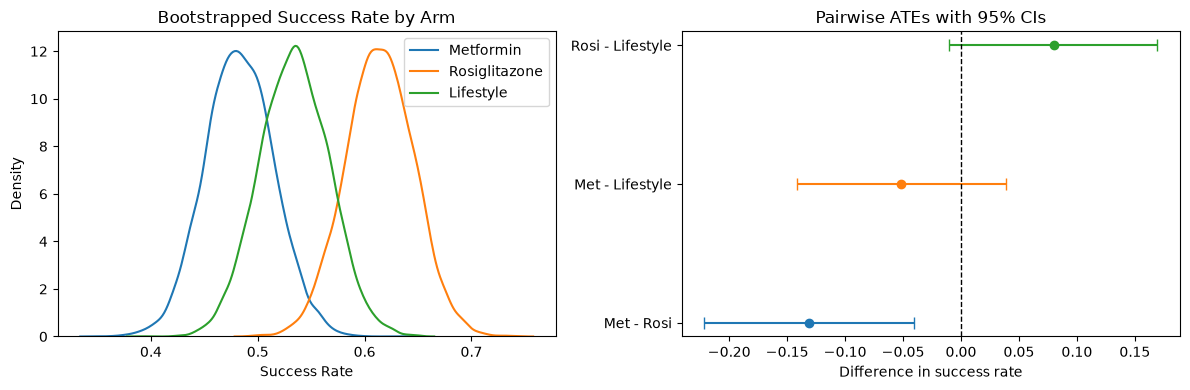

In [9]:
## Report figures: success rates by arm, pairwise ATEs with 95% CIs

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', ax=ax[0]).set(title='Bootstrapped Success Rate by Arm', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

for name, ate in ates.items():
    ci95 = np.quantile(ate, [.025, .975])
    ax[1].errorbar(ate.mean(), name, xerr=[[ate.mean() - ci95[0]], [ci95[1] - ate.mean()]], fmt='o', capsize=4)
ax[1].axvline(0, color='black', linestyle='--', linewidth=1)
ax[1].set_xlabel('Difference in success rate')
ax[1].set_title('Pairwise ATEs with 95% CIs')

plt.tight_layout()
plt.show()